## Imports

In [49]:
import io
import glob
import os
import pandas as pd
import numpy as np
import requests
import holidays
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf



## Config

In [50]:
DATA_INICIO = "2021-01-01"

DATA_FIM = (datetime.now() - timedelta(days=5)).strftime("%Y-%m-%d")
ANOS = list(range(2021, datetime.now().year + 1))

HEADERS = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"
}

### (Verificar se esses são realmente polos industriais)Polos demográficos e industriais do Subsistema Sul (PR, SC, RS)
POLOS_SUL = [
    {"nome": "Curitiba_PR",     "lat": -25.4284, "lon": -49.2733, "peso": 0.25},
    {"nome": "Londrina_PR",     "lat": -23.3045, "lon": -51.1696, "peso": 0.15},
    {"nome": "PortoAlegre_RS",  "lat": -30.0346, "lon": -51.2177, "peso": 0.20},
    {"nome": "CaxiasDoSul_RS",  "lat": -29.1678, "lon": -51.1794, "peso": 0.15},
    {"nome": "Joinville_SC",    "lat": -26.3045, "lon": -48.8487, "peso": 0.15},
    {"nome": "Chapeco_SC",      "lat": -27.1004, "lon": -52.6152, "peso": 0.10},
]

### Primeira parte
ONS

In [51]:
def obter_urls_ons_ckan() -> dict:
    urls_por_ano = {}
    try:
        api_url = "https://dados.ons.org.br/api/3/action/package_show?id=curva-carga"
        resp = requests.get(api_url, headers=HEADERS, timeout=30)
        resp.raise_for_status()
        recursos = resp.json()["result"]["resources"]
        for rec in recursos:
            url = rec.get("url", "")
            if url.lower().endswith(".csv"):
                for ano in ANOS:
                    if str(ano) in url:
                        urls_por_ano[ano] = url
    except Exception as e:
        print(f"  [INFO] Não foi possível consultar a API CKAN ({e}). Usando URL padrão S3.")
    return urls_por_ano

def carregar_dados_ons(anos: list) -> pd.DataFrame:
    dfs = []
    urls_ckan = obter_urls_ons_ckan()
    
    ### Se nao existir a pasta de dados brutos ela será criada
    os.makedirs("data/raw", exist_ok=True)
    
    for ano in anos:
        url = urls_ckan.get(
            ano,
            f"https://ons-aws-prod-opendata.s3.amazonaws.com/dataset/curva_carga_ho/CURVA_CARGA_{ano}.csv"
        )
        caminho_local = f"data/raw/CURVA_CARGA_{ano}.csv"
        
        try:
            if os.path.exists(caminho_local):
                df_ano = pd.read_csv(caminho_local, sep=";", decimal=".")
                origem = "cache local"
            else:
                resp = requests.get(url, headers=HEADERS, timeout=60)
                resp.raise_for_status()
                with open(caminho_local, "wb") as f:
                    f.write(resp.content)
                df_ano = pd.read_csv(io.BytesIO(resp.content), sep=";", decimal=".")
                origem = "portal ONS"
                
            ### Filtra apenas o Subsistema Sul
            df_sul = df_ano[df_ano["id_subsistema"].str.strip() == "S"].copy()
            dfs.append(df_sul)
            print(f"Ano {ano} ({origem}): {len(df_sul)} registros horários carregados.")
        except Exception as e:
            print(f"Não foi possível baixar o ano {ano}: {e}")

    if not dfs:
        raise RuntimeError(
            "Nenhum arquivo do ONS foi carregado. Verifique sua conexão ou baixe os CSVs de "
            "'Curva de Carga Horária' em https://dados.ons.org.br/dataset/curva-carga para a pasta data/raw/."
        )
    df_ons = pd.concat(dfs, ignore_index=True)

    ### Tentando achar a coluna de carga
    cols_carga = [c for c in df_ons.columns if "val_carga" in c.lower()]
    if not cols_carga:
        raise KeyError(f"Coluna de carga não encontrada. Colunas disponíveis: {list(df_ons.columns)}")
    col_carga = cols_carga[0]
    print(f"Coluna de carga: '{col_carga}'")

    ### Padronização de data/hora e valores numéricos
    df_ons["data_hora"] = pd.to_datetime(df_ons["din_instante"])
    df_ons["carga_mwmed"] = pd.to_numeric(df_ons[col_carga], errors="coerce")

    ### Ordenação e remoção de duplicados
    df_ons = df_ons.sort_values("data_hora").drop_duplicates(subset=["data_hora"], keep="first")

    ### Agregação horária explícita (garante granularidade de 1h)
    df_ons = (
        df_ons.set_index("data_hora")[["carga_mwmed"]]
        .resample("1h")
        .mean()
    )

    ### Tratamento de valores suspeitos (carga <= 0 ou aumento de mais de 35% em uma hora)
    pct_change = df_ons["carga_mwmed"].pct_change(fill_method=None).abs()
    anomalias = (df_ons["carga_mwmed"] <= 0)
    print(f"Valores estranhos: {anomalias.sum()}")
    df_ons.loc[anomalias, "carga_mwmed"] = np.nan

    ### Tratamento de ausentes (Não ta servindo pra nada)
    ausentes_antes = df_ons["carga_mwmed"].isna().sum()
    df_ons["carga_mwmed"] = df_ons["carga_mwmed"].interpolate(method="linear", limit=3)
    df_ons["carga_mwmed"] = df_ons["carga_mwmed"].fillna(df_ons["carga_mwmed"].shift(168))
    ausentes_depois = df_ons["carga_mwmed"].isna().sum()
    print(f"Ausentes ONS antes: {ausentes_antes} | após tratamento: {ausentes_depois}")

    return df_ons.reset_index()

In [52]:
def carregar_dados_clima(polos: list, start_date: str, end_date: str) -> pd.DataFrame:
    url = "https://archive-api.open-meteo.com/v1/archive"
    
    df_clima_total = None
    temps_cols = []
    
    for polo in polos:
        params = {
            "latitude": polo["lat"],
            "longitude": polo["lon"],
            "start_date": start_date,
            "end_date": end_date,
            "hourly": "temperature_2m,relative_humidity_2m",
            "timezone": "America/Sao_Paulo"
        }
        resp = requests.get(url, params=params, timeout=60)
        resp.raise_for_status()
        dados = resp.json()["hourly"]
        
        col_temp = f"temp_{polo['nome']}"
        col_umid = f"umid_{polo['nome']}"
        temps_cols.append(col_temp)
        
        df_polo = pd.DataFrame({
            "data_hora": pd.to_datetime(dados["time"]),
            col_temp: dados["temperature_2m"],
            col_umid: dados["relative_humidity_2m"],
        })
        
        if df_clima_total is None:
            df_clima_total = df_polo
        else:
            df_clima_total = pd.merge(df_clima_total, df_polo, on="data_hora", how="outer")
        print(f"Polo {polo['nome']} integrado.")
        
    df_clima_total = df_clima_total.sort_values("data_hora").interpolate(method="linear", limit=3)
    
    # Agregação espacial ponderada
    df_clima_total["temp_sul_ponderada"] = sum(
        df_clima_total[f"temp_{p['nome']}"] * p["peso"] for p in polos
    )
    df_clima_total["umidade_sul_ponderada"] = sum(
        df_clima_total[f"umid_{p['nome']}"] * p["peso"] for p in polos
    )
    
    # Extremos simultâneos entre os polos do Sul
    df_clima_total["temp_min_polos"] = df_clima_total[temps_cols].min(axis=1)
    df_clima_total["temp_max_polos"] = df_clima_total[temps_cols].max(axis=1)
    
    # Graus-dia de Aquecimento (HDD) e Resfriamento (CDD)
    df_clima_total["hdd"] = np.maximum(0, 18.0 - df_clima_total["temp_sul_ponderada"])
    df_clima_total["cdd"] = np.maximum(0, df_clima_total["temp_sul_ponderada"] - 26.0)
    
    colunas_finais = [
        "data_hora", "temp_sul_ponderada", "temp_min_polos", "temp_max_polos",
        "umidade_sul_ponderada", "hdd", "cdd"
    ]
    return df_clima_total[colunas_finais]

In [53]:
def criar_features_calendario(df: pd.DataFrame) -> pd.DataFrame:
    datas = df["data_hora"].dt.date
    
    feriados_br = holidays.Brazil(years=ANOS)
    feriados_pr = holidays.Brazil(subdiv="PR", years=ANOS)
    feriados_sc = holidays.Brazil(subdiv="SC", years=ANOS)
    feriados_rs = holidays.Brazil(subdiv="RS", years=ANOS)
    
    df["is_feriado_nacional"] = datas.isin(feriados_br).astype("int8")
    
    is_est = (
        datas.isin(feriados_pr) | datas.isin(feriados_sc) | datas.isin(feriados_rs)
    ) & (~datas.isin(feriados_br))
    df["is_feriado_estadual_sul"] = is_est.astype("int8")
    
    df["dia_semana"] = df["data_hora"].dt.dayofweek.astype("int8")
    df["hora"] = df["data_hora"].dt.hour.astype("int8")
    df["mes"] = df["data_hora"].dt.month.astype("int8")
    df["is_fim_de_semana"] = (df["dia_semana"] >= 5).astype("int8")
    
    ontem_feriado = (df["data_hora"] - pd.Timedelta(days=1)).dt.date.isin(feriados_br)
    amanha_feriado = (df["data_hora"] + pd.Timedelta(days=1)).dt.date.isin(feriados_br)
    df["is_ponte"] = (
        ((df["dia_semana"] == 0) & amanha_feriado) |
        ((df["dia_semana"] == 4) & ontem_feriado)
    ).astype("int8")
    
    df["extremo_frio"] = (df["temp_sul_ponderada"] < 6.0).astype("int8")
    df["extremo_calor"] = (df["temp_sul_ponderada"] > 30.0).astype("int8")
    
    qualquer_feriado = (df["is_feriado_nacional"] == 1) | (df["is_feriado_estadual_sul"] == 1)
    qualquer_extremo = (df["extremo_frio"] == 1) | (df["extremo_calor"] == 1)
    df["interacao_feriado_extremo"] = (qualquer_feriado & qualquer_extremo).astype("int8")
    
    try:
        url_ibge = "https://apisidra.ibge.gov.br/values/t/8888/n2/4/v/12606/p/all/c544/129314?formato=json"
        r_ibge = requests.get(url_ibge, timeout=30).json()
        df_ibge = pd.DataFrame(r_ibge[1:])[["D3C", "V"]].rename(
            columns={"D3C": "ano_mes", "V": "indice_pim_sul"}
        )
        df_ibge["indice_pim_sul"] = pd.to_numeric(df_ibge["indice_pim_sul"], errors="coerce")
        df["ano_mes"] = df["data_hora"].dt.strftime("%Y%m")
        df = pd.merge(df, df_ibge, on="ano_mes", how="left")
        df["indice_pim_sul"] = df["indice_pim_sul"].ffill()
        df = df.drop(columns=["ano_mes"])
        print("Indicador Industrial PIM-PF (IBGE Sul) integrado.")
    except Exception as e:
        print(f"Deu errado na busca do IBGE SIDRA ({e}). Seguindo sem indicador mensal.")
        
    return df

## Pipeline de execução do projeto

In [54]:


df_ons = carregar_dados_ons(ANOS)
df_clima = carregar_dados_clima(POLOS_SUL, DATA_INICIO, DATA_FIM)

df_final = pd.merge(df_ons, df_clima, on="data_hora", how="inner")
df_final = df_final[
    (df_final["data_hora"] >= DATA_INICIO) & (df_final["data_hora"] <= f"{DATA_FIM} 23:00:00")
].copy()

df_final = criar_features_calendario(df_final)

os.makedirs("data/processed", exist_ok=True)
df_final = df_final.sort_values("data_hora").reset_index(drop=True)
arquivo_saida = "data/processed/dataset_sul.parquet"
df_final.to_parquet(arquivo_saida, engine="pyarrow", index=False)

print("Pipeline concluído com sucesso!")
print(f"Arquivo exportado: {arquivo_saida}")
print(f"Dimensões da base (linhas, colunas): {df_final.shape}")
print(f"Período coberto: {df_final['data_hora'].min()} até {df_final['data_hora'].max()}")
print(f"Total de valores nulos restantes:\n{df_final.isna().sum()[df_final.isna().sum() > 0]}")

Ano 2021 (cache local): 8760 registros horários carregados.
Ano 2022 (cache local): 8760 registros horários carregados.
Ano 2023 (cache local): 8760 registros horários carregados.
Ano 2024 (cache local): 8784 registros horários carregados.
Ano 2025 (cache local): 8760 registros horários carregados.
Ano 2026 (cache local): 7632 registros horários carregados.
Coluna de carga: 'val_cargaenergiahomwmed'
Valores estranhos: 0
Ausentes ONS antes: 0 | após tratamento: 0


ConnectionError: HTTPSConnectionPool(host='archive-api.open-meteo.com', port=443): Max retries exceeded with url: /v1/archive?latitude=-25.4284&longitude=-49.2733&start_date=2021-01-01&end_date=2026-11-18&hourly=temperature_2m%2Crelative_humidity_2m&timezone=America%2FSao_Paulo (Caused by NameResolutionError("HTTPSConnection(host='archive-api.open-meteo.com', port=443): Failed to resolve 'archive-api.open-meteo.com' ([Errno 11001] getaddrinfo failed)"))

### Por algum motivo esse campo não tinha dados então precisei de ajuda para pegá-los de outra forma

In [56]:
url_ibge = "https://apisidra.ibge.gov.br/values/t/8888/n2/4/v/12606/p/all/c544/129314?formato=json"
r_ibge = requests.get(url_ibge, timeout=30).json()
### Verifica se a API retornou dados válidos; se não, remove a coluna vazia
if df_final["indice_pim_sul"].isna().all():
    df_final = df_final.drop(columns=["indice_pim_sul"])
    df_final.to_parquet("data/processed/dataset_sul.parquet", engine="pyarrow", index=False)
    print("Coluna 'indice_pim_sul' removida por indisponibilidade na API. Parquet atualizado (18 colunas).")

KeyError: 'indice_pim_sul'

### Pergunta: indice_pim_sul é confiável?
R: sim, é do IBGE

In [ ]:
df_final

,data_hora,carga_mwmed,temp_sul_ponderada,temp_min_polos,temp_max_polos,umidade_sul_ponderada,hdd,cdd,is_feriado_nacional,is_feriado_estadual_sul,dia_semana,hora,mes,is_fim_de_semana,is_ponte,extremo_frio,extremo_calor,interacao_feriado_extremo
0,2021-01-01 00:00:00,9060.566986,19.680,14.8,23.4,88.30,0.0,0.0,1,0,4,0,1,0,0,0,0,0
1,2021-01-01 01:00:00,9020.190988,19.365,14.6,22.9,89.35,0.0,0.0,1,0,4,1,1,0,0,0,0,0
2,2021-01-01 02:00:00,8696.537996,19.080,14.5,22.7,89.90,0.0,0.0,1,0,4,2,1,0,0,0,0,0
3,2021-01-01 03:00:00,8338.067001,18.735,14.5,22.5,91.50,0.0,0.0,1,0,4,3,1,0,0,0,0,0
4,2021-01-01 04:00:00,8081.066000,18.410,14.4,22.2,92.85,0.0,0.0,1,0,4,4,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51451,2026-11-14 19:00:00,16462.507000,21.665,18.9,23.5,87.30,0.0,0.0,0,0,5,19,11,1,0,0,0,0
51452,2026-11-14 20:00:00,15937.056000,20.915,18.2,22.9,90.40,0.0,0.0,0,0,5,20,11,1,0,0,0,0
51453,2026-11-14 21:00:00,15219.622000,20.975,18.8,22.7,89.10,0.0,0.0,0,0,5,21,11,1,0,0,0,0
51454,2026-11-14 22:00:00,14385.832000,20.590,18.5,22.1,90.65,0.0,0.0,0,0,5,22,11,1,0,0,0,0


## Anotações
Lembrar de trocar os nomes das colunas.

# 3ª parte

In [57]:

df = pd.read_parquet("data/processed/dataset_sul.parquet")
sns.set_theme(style="whitegrid", context="notebook")

def ic_95(serie: pd.Series):
    n = len(serie)
    media = serie.mean()
    erro_padrao = stats.sem(serie)
    margem = erro_padrao * stats.t.ppf(0.975, df=n - 1)
    return media, media - margem, media + margem

### Primeira hipotese
frio = df.loc[df["extremo_frio"] == 1, "carga_mwmed"]
ameno = df.loc[(df["extremo_frio"] == 0) & (df["extremo_calor"] == 0), "carga_mwmed"]
calor = df.loc[df["extremo_calor"] == 1, "carga_mwmed"]

print("=== HIPÓTESE 1: EFEITO TÉRMICO BIMODAL ===")
for nome, grupo in [("Frio Extremo (<6°C)", frio), ("Clima Ameno (6-30°C)", ameno), ("Calor Extremo (>30°C)", calor)]:
    m, low, high = ic_95(grupo)
    print(f"{nome:22s} | Média: {m:8.2f} MW | IC 95%: [{low:8.2f}, {high:8.2f}] | n={len(grupo)}")


t_frio, p_frio = stats.ttest_ind(frio, ameno, equal_var=False)
t_calor, p_calor = stats.ttest_ind(calor, ameno, equal_var=False)
print(f"Frio vs. Ameno  -> t = {t_frio:.2f}, p-valor = {p_frio:.4e}")
print(f"Calor vs. Ameno -> t = {t_calor:.2f}, p-valor = {p_calor:.4e}\n")

### Segunda hipotese
df["temp_lag_24h"] = df["temp_sul_ponderada"].shift(24)
df["temp_media_72h"] = df["temp_sul_ponderada"].rolling(72).mean()
df["cdd_acumulado_72h"] = df["cdd"].rolling(72).sum()
df["hdd_acumulado_72h"] = df["hdd"].rolling(72).sum()

df_valid = df.dropna(subset=["temp_lag_24h", "temp_media_72h"]).copy()

# Correlação parcial / incremental em dias quentes (CDD > 0) e frios (HDD > 0)
r_inst, p_inst = stats.pearsonr(df_valid.loc[df_valid["cdd"] > 0, "cdd"], df_valid.loc[df_valid["cdd"] > 0, "carga_mwmed"])
r_acum, p_acum = stats.pearsonr(df_valid.loc[df_valid["cdd"] > 0, "cdd_acumulado_72h"], df_valid.loc[df_valid["cdd"] > 0, "carga_mwmed"])

print("=== HIPÓTESE 2: INÉRCIA TÉRMICA ===")
print(f"Correlação CDD instantâneo vs. Carga : r = {r_inst:.4f} (p = {p_inst:.4e})")
print(f"Correlação CDD acumulado 72h vs. Carga: r = {r_acum:.4f} (p = {p_acum:.4e})\n")

### Terceira hipotese
df["qualquer_feriado"] = ((df["is_feriado_nacional"] == 1) | (df["is_feriado_estadual_sul"] == 1)).astype(int)
df["qualquer_extremo"] = ((df["extremo_frio"] == 1) | (df["extremo_calor"] == 1)).astype(int)

feriado_ameno = df.loc[(df["qualquer_feriado"] == 1) & (df["qualquer_extremo"] == 0), "carga_mwmed"]
feriado_extremo = df.loc[(df["qualquer_feriado"] == 1) & (df["qualquer_extremo"] == 1), "carga_mwmed"]

m_fa, l_fa, h_fa = ic_95(feriado_ameno)
m_fe, l_fe, h_fe = ic_95(feriado_extremo)
t_h3, p_h3 = stats.ttest_ind(feriado_extremo, feriado_ameno, equal_var=False)

print("=== HIPÓTESE 3: FERIADOS EM EXTREMOS TÉRMICOS ===")
print(f"Feriado + Clima Ameno   | Média: {m_fa:8.2f} MW | IC 95%: [{l_fa:8.2f}, {h_fa:8.2f}] | n={len(feriado_ameno)}")
print(f"Feriado + Extremo Term. | Média: {m_fe:8.2f} MW | IC 95%: [{l_fe:8.2f}, {h_fe:8.2f}] | n={len(feriado_extremo)}")
print(f"Diferença média: +{m_fe - m_fa:.2f} MW (+{(m_fe/m_fa - 1)*100:.2f}%) | t = {t_h3:.2f}, p-valor = {p_h3:.4e}")

# Regressão Linear com Termo de Interação
modelo_h3 = smf.ols(
    "carga_mwmed ~ qualquer_feriado * qualquer_extremo + C(hora) + is_fim_de_semana",
    data=df
).fit(cov_type="HC3")
print("\nCoeficiente de Interação (qualquer_feriado:qualquer_extremo):")
print(modelo_h3.summary().tables[1])


=== HIPÓTESE 1: EFEITO TÉRMICO BIMODAL ===
Frio Extremo (<6°C)    | Média: 10783.79 MW | IC 95%: [10514.80, 11052.78] | n=220
Clima Ameno (6-30°C)   | Média: 12904.35 MW | IC 95%: [12881.50, 12927.19] | n=50850
Calor Extremo (>30°C)  | Média: 17078.67 MW | IC 95%: [16756.84, 17400.50] | n=386
Frio vs. Ameno  -> t = -15.48, p-valor = 3.6706e-37
Calor vs. Ameno -> t = 25.44, p-valor = 9.2796e-85

=== HIPÓTESE 2: INÉRCIA TÉRMICA ===
Correlação CDD instantâneo vs. Carga : r = 0.1316 (p = 9.6516e-03)
Correlação CDD acumulado 72h vs. Carga: r = 0.1684 (p = 8.9791e-04)

=== HIPÓTESE 3: FERIADOS EM EXTREMOS TÉRMICOS ===
Feriado + Clima Ameno   | Média: 10842.71 MW | IC 95%: [10745.85, 10939.56] | n=1701
Feriado + Extremo Term. | Média:  8652.42 MW | IC 95%: [ 8360.31,  8944.54] | n=3
Diferença média: +-2190.28 MW (+-20.20%) | t = -26.09, p-valor = 3.0366e-06

Coeficiente de Interação (qualquer_feriado:qualquer_extremo):
                                        coef    std err          z      P>

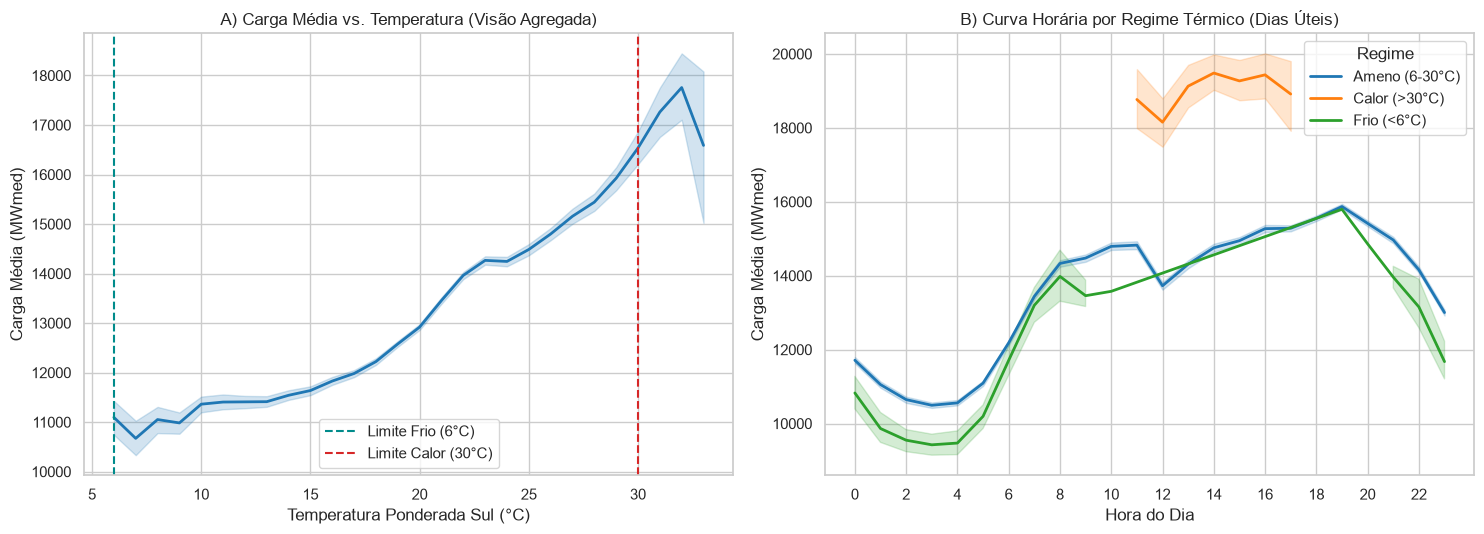

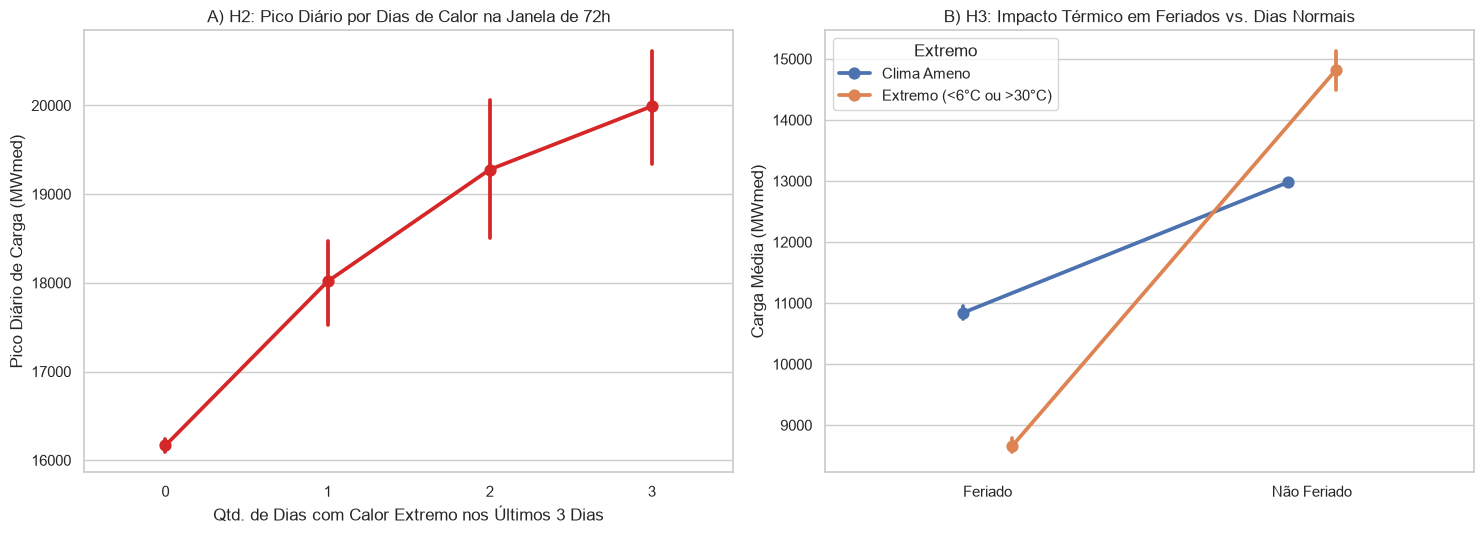

In [ ]:


df = pd.read_parquet("data/processed/dataset_sul.parquet")
sns.set_theme(style="whitegrid", context="notebook")

LIMITE_FRIO = 6.0
LIMITE_CALOR = 30.0

df["extremo_frio"] = (df["temp_sul_ponderada"] < LIMITE_FRIO).astype(int)
df["extremo_calor"] = (df["temp_sul_ponderada"] > LIMITE_CALOR).astype(int)
df["qualquer_feriado"] = ((df["is_feriado_nacional"] == 1) | (df["is_feriado_estadual_sul"] == 1)).astype(int)
df["qualquer_extremo"] = ((df["extremo_frio"] == 1) | (df["extremo_calor"] == 1)).astype(int)


### Hipotese 1: Uso com calor e frio extremos

fig1, axes1 = plt.subplots(1, 2, figsize=(15, 5.5))

# Painel A: Curva Temperatura x Carga
df["faixa_temp"] = df["temp_sul_ponderada"].round()
sns.lineplot(
    data=df[(df["faixa_temp"] >= 6) & (df["faixa_temp"] <= 34)],
    x="faixa_temp", y="carga_mwmed", errorbar=("ci", 95), ax=axes1[0], color="#1f77b4", linewidth=2
)
axes1[0].axvline(LIMITE_FRIO, color="#008b8b", linestyle="--", label=f"Limite Frio ({LIMITE_FRIO:.0f}°C)")
axes1[0].axvline(LIMITE_CALOR, color="#d62728", linestyle="--", label=f"Limite Calor ({LIMITE_CALOR:.0f}°C)")
axes1[0].set_title("A) Carga Média vs. Temperatura (Visão Agregada)")
axes1[0].set_xlabel("Temperatura Ponderada Sul (°C)")
axes1[0].set_ylabel("Carga Média (MWmed)")
axes1[0].legend()

# Painel B: Curva Horária por Regime (Desfazendo o viés de horário)
df["Regime"] = np.where(
    df["extremo_frio"] == 1, f"Frio (<{LIMITE_FRIO:.0f}°C)",
    np.where(df["extremo_calor"] == 1, f"Calor (>{LIMITE_CALOR:.0f}°C)", f"Ameno ({LIMITE_FRIO:.0f}-{LIMITE_CALOR:.0f}°C)")
)
sns.lineplot(
    data=df[df["is_fim_de_semana"] == 0],
    x="hora", y="carga_mwmed", hue="Regime",
    palette={f"Ameno ({LIMITE_FRIO:.0f}-{LIMITE_CALOR:.0f}°C)": "#1f77b4",
             f"Calor (>{LIMITE_CALOR:.0f}°C)": "#ff7f0e",
             f"Frio (<{LIMITE_FRIO:.0f}°C)": "#2ca02c"},
    errorbar=("ci", 95), ax=axes1[1], linewidth=2
)
axes1[1].set_title("B) Curva Horária por Regime Térmico (Dias Úteis)")
axes1[1].set_xlabel("Hora do Dia")
axes1[1].set_ylabel("Carga Média (MWmed)")
axes1[1].set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.savefig("figura1_hipotese1_bimodal.png", dpi=300)
plt.show()

### Hipotese 2: Lag de temperatura hipotese 3: feriados

fig2, axes2 = plt.subplots(1, 2, figsize=(15, 5.5))

# Painel A: Hipótese 2 - Acúmulo de dias consecutivos de calor (Inércia Térmica)
df_diario = (
    df[df["is_fim_de_semana"] == 0]
    .assign(dia=df["data_hora"].dt.date)
    .groupby("dia", as_index=False)
    .agg(pico_diario=("carga_mwmed", "max"), teve_calor=("extremo_calor", "max"))
)
df_diario["dias_calor_3d"] = df_diario["teve_calor"].rolling(3, min_periods=1).sum().astype(int)

sns.pointplot(
    data=df_diario, x="dias_calor_3d", y="pico_diario",
    errorbar=("ci", 95), color="#d62728", ax=axes2[0]
)
axes2[0].set_title("A) H2: Pico Diário por Dias de Calor na Janela de 72h")
axes2[0].set_xlabel("Qtd. de Dias com Calor Extremo nos Últimos 3 Dias")
axes2[0].set_ylabel("Pico Diário de Carga (MWmed)")

# Painel B: Hipótese 3 - Interação Feriado x Extremo Térmico
df["Tipo_Dia"] = np.where(df["qualquer_feriado"] == 1, "Feriado", "Não Feriado")
df["Extremo"] = np.where(df["qualquer_extremo"] == 1, f"Extremo (<{LIMITE_FRIO:.0f}°C ou >{LIMITE_CALOR:.0f}°C)", "Clima Ameno")

sns.pointplot(
    data=df, x="Tipo_Dia", y="carga_mwmed", hue="Extremo",
    errorbar=("ci", 95), dodge=0.15, ax=axes2[1]
)
axes2[1].set_title("B) H3: Impacto Térmico em Feriados vs. Dias Normais")
axes2[1].set_xlabel("")
axes2[1].set_ylabel("Carga Média (MWmed)")

plt.tight_layout()
plt.savefig("figura2_hipoteses2_e_3.png", dpi=300)
plt.show()